Cell 1: clone the repo and install its requirements

In [1]:
!git clone https://github.com/amazon-science/patchcore-inspection.git
%cd /content/patchcore-inspection
!git rev-parse HEAD
!pip install -q faiss-cpu pretrainedmodels click scikit-image

Cloning into 'patchcore-inspection'...
remote: Enumerating objects: 365, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 365 (delta 13), reused 8 (delta 8), pack-reused 329 (from 1)
Receiving objects: 100% (365/365), 2.02 MiB | 33.92 MiB/s, done.
Resolving deltas: 100% (56/56), done.
/content/patchcore-inspection
fcaa92f124fb1ad74a7acf56726decd4b27cbcad
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 4.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 95.1 MB/s eta 0:00:00


Cell 2: Drive and environment record

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, json, subprocess, datetime, torch, torchvision, faiss
OUT_DIR = "/content/drive/MyDrive/COMP8240_PatchCore/step2_official_repo"
os.makedirs(OUT_DIR, exist_ok=True)

env = {
    "date": datetime.datetime.now().isoformat(timespec="minutes"),
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "faiss": faiss.__version__,
    "gpu": torch.cuda.get_device_name(0),
    "repo_commit": subprocess.check_output(["git", "rev-parse", "HEAD"]).decode().strip(),
}
print(json.dumps(env, indent=2))
json.dump(env, open(f"{OUT_DIR}/environment.json", "w"), indent=2)

Mounted at /content/drive
{
  "date": "2026-10-04T10:06",
  "python": "3.13.15",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "faiss": "1.15.1",
  "gpu": "Tesla T4",
  "repo_commit": "fcaa92f124fb1ad74a7acf56726decd4b27cbcad"
}


Cell 3: get MVTec AD

In [3]:
# only using anomalib's downloader to fetch the dataset, PatchCore itself runs from the authors' code
!pip install -q anomalib
from anomalib.data import MVTecAD
MVTecAD(root="/content/datasets/MVTecAD", category="bottle").prepare_data()
!ls /content/datasets/MVTecAD

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 29.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 246.1/246.1 kB 25.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 74.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 62.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 69.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.1/28.1 MB 76.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 123.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 800.2/800.2 kB 60.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 61.6 MB/s eta 0:00:00


mvtecad: 5.26GB [03:55, 22.4MB/s]                            


bottle	 carpet    leather	pill	    tile	wood
cable	 grid	   license.txt	readme.txt  toothbrush	zipper
capsule  hazelnut  metal_nut	screw	    transistor


Cell 4: test run on bottle only

In [4]:
%%bash
cd /content/patchcore-inspection
datapath=/content/datasets/MVTecAD

time PYTHONPATH=src python bin/run_patchcore.py --gpu 0 --seed 0 \
  --log_group WR50_L2-3_P01_S0_bottle --log_project official results \
  patch_core -b wideresnet50 -le layer2 -le layer3 \
  --pretrain_embed_dimension 1024 --target_embed_dimension 1024 \
  --anomaly_scorer_num_nn 1 --patchsize 3 \
  sampler -p 0.1 approx_greedy_coreset \
  dataset --resize 256 --imagesize 224 -d bottle mvtec $datapath

Downloading: "https://download.pytorch.org/models/wide_resnet50_2-95faca4d.pth" to /root/.cache/torch/hub/checkpoints/wide_resnet50_2-95faca4d.pth


INFO:__main__:Command line arguments: bin/run_patchcore.py --gpu 0 --seed 0 --log_group WR50_L2-3_P01_S0_bottle --log_project official results patch_core -b wideresnet50 -le layer2 -le layer3 --pretrain_embed_dimension 1024 --target_embed_dimension 1024 --anomaly_scorer_num_nn 1 --patchsize 3 sampler -p 0.1 approx_greedy_coreset dataset --resize 256 --imagesize 224 -d bottle mvtec /content/datasets/MVTecAD
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
INFO:__main__:Evaluating dataset [mvtec_bottle] (1/1)...
/usr/local/lib/python3.13/dist-packages/torchvision/mo

In [5]:
%%bash
cd /content/patchcore-inspection
datapath=/content/datasets/MVTecAD
datasets=('bottle' 'cable' 'capsule' 'carpet' 'grid' 'hazelnut' 'leather' 'metal_nut' 'pill' 'screw' 'tile' 'toothbrush' 'transistor' 'wood' 'zipper')
dataset_flags=($(for d in "${datasets[@]}"; do echo '-d '$d; done))

time PYTHONPATH=src python bin/run_patchcore.py --gpu 0 --seed 0 \
  --log_group WR50_L2-3_P01_S0_all --log_project official results \
  patch_core -b wideresnet50 -le layer2 -le layer3 \
  --pretrain_embed_dimension 1024 --target_embed_dimension 1024 \
  --anomaly_scorer_num_nn 1 --patchsize 3 \
  sampler -p 0.1 approx_greedy_coreset \
  dataset --resize 256 --imagesize 224 "${dataset_flags[@]}" mvtec $datapath

INFO:__main__:Command line arguments: bin/run_patchcore.py --gpu 0 --seed 0 --log_group WR50_L2-3_P01_S0_all --log_project official results patch_core -b wideresnet50 -le layer2 -le layer3 --pretrain_embed_dimension 1024 --target_embed_dimension 1024 --anomaly_scorer_num_nn 1 --patchsize 3 sampler -p 0.1 approx_greedy_coreset dataset --resize 256 --imagesize 224 -d bottle -d cable -d capsule -d carpet -d grid -d hazelnut -d leather -d metal_nut -d pill -d screw -d tile -d toothbrush -d transistor -d wood -d zipper mvtec /content/datasets/MVTecAD
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.che

In [6]:
import glob, shutil
import pandas as pd

for f in glob.glob("/content/patchcore-inspection/results/official/**/results.csv", recursive=True):
    print(f)
    display(pd.read_csv(f))
    shutil.copy(f, f"{OUT_DIR}/{f.split('/')[-2]}_results.csv")

/content/patchcore-inspection/results/official/WR50_L2-3_P01_S0_bottle/results.csv


,Row Names,instance_auroc,full_pixel_auroc,anomaly_pixel_auroc
0,mvtec_bottle,1.0,0.984839,0.979561
1,Mean,1.0,0.984839,0.979561


/content/patchcore-inspection/results/official/WR50_L2-3_P01_S0_all/results.csv


,Row Names,instance_auroc,full_pixel_auroc,anomaly_pixel_auroc
0,mvtec_bottle,1.000000,0.984839,0.979561
1,mvtec_cable,0.996814,0.984137,0.975283
2,mvtec_capsule,0.979258,0.989544,0.987421
3,mvtec_carpet,0.985955,0.990514,0.987866
4,mvtec_grid,0.979114,0.988008,0.983662
5,mvtec_hazelnut,1.000000,0.986768,0.979133
6,mvtec_leather,1.000000,0.992877,0.990377
7,mvtec_metal_nut,0.999022,0.983403,0.979224
8,mvtec_pill,0.966721,0.978012,0.976050
9,mvtec_screw,0.987702,0.995248,0.993828


Cell 7: load the official results and build the comparison tables

In [7]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CATEGORIES = ["bottle", "cable", "capsule", "carpet", "grid", "hazelnut", "leather", "metal_nut",
              "pill", "screw", "tile", "toothbrush", "transistor", "wood", "zipper"]

# paper PatchCore-10% (image AUROC, pixel AUROC), supplementary Tables S1 and S2
PAPER = {
    "bottle": (100.0, 98.6), "cable": (99.4, 98.5), "capsule": (97.8, 98.9),
    "carpet": (98.7, 99.1), "grid": (97.9, 98.7), "hazelnut": (100.0, 98.7),
    "leather": (100.0, 99.3), "metal_nut": (100.0, 98.4), "pill": (96.0, 97.6),
    "screw": (97.0, 99.4), "tile": (98.9, 95.9), "toothbrush": (99.7, 98.7),
    "transistor": (100.0, 96.4), "wood": (99.0, 95.1), "zipper": (99.5, 98.9),
}
ANOMALIB_CSV = "/content/drive/MyDrive/COMP8240_PatchCore/step1_mvtec/mvtec_results.csv"

f = sorted(p for p in glob.glob("/content/patchcore-inspection/results/official/**/results.csv", recursive=True)
           if "_all" in p)[-1]
raw = pd.read_csv(f)
print(f); print(raw.columns.tolist())

def col(key):
    return next(c for c in raw.columns if key in c.lower().replace("_", " "))

off = pd.DataFrame({
    "image_AUROC": raw[col("instance")].values,
    "pixel_AUROC": raw[col("full pixel")].values,
    "anomaly_pixel_AUROC": raw[col("anomaly pixel")].values,
}, index=raw[raw.columns[0]].astype(str).str.replace("mvtec_", "", regex=False))
off = off.loc[[c for c in CATEGORIES if c in off.index]].astype(float)
if off.max().max() <= 1:
    off *= 100

anom = pd.read_csv(ANOMALIB_CSV).query("tag == 'main'").set_index("category").loc[CATEGORIES]

comp = pd.DataFrame({
    "paper_img": [PAPER[c][0] for c in CATEGORIES],
    "official_img": off["image_AUROC"],
    "anomalib_img": anom["image_AUROC"] * 100,
    "paper_pix": [PAPER[c][1] for c in CATEGORIES],
    "official_pix": off["pixel_AUROC"],
    "anomalib_pix": anom["pixel_AUROC"] * 100,
}, index=CATEGORIES)
comp.loc["MEAN"] = comp.mean()
comp = comp.round(1)

summary = pd.DataFrame({
    "Image AUROC": [99.0, 99.2, comp.loc["MEAN", "official_img"], comp.loc["MEAN", "anomalib_img"]],
    "Pixel AUROC": [98.1, 98.1, comp.loc["MEAN", "official_pix"], comp.loc["MEAN", "anomalib_pix"]],
}, index=["Paper, PatchCore-10% (Tables 1-2)", "Repo README, WR50 baseline",
          "Official code (my run)", "Anomalib 2.6.2 (my run)"])

display(comp); display(summary)
comp.to_csv(f"{OUT_DIR}/comparison_per_category.csv")
summary.to_csv(f"{OUT_DIR}/comparison_summary.csv")
# LaTeX versions to paste straight into the Overleaf report
comp.to_latex(f"{OUT_DIR}/comparison_per_category.tex", float_format="%.1f")
summary.to_latex(f"{OUT_DIR}/comparison_summary.tex", float_format="%.1f")

/content/patchcore-inspection/results/official/WR50_L2-3_P01_S0_all/results.csv
['Row Names', 'instance_auroc', 'full_pixel_auroc', 'anomaly_pixel_auroc']


,paper_img,official_img,anomalib_img,paper_pix,official_pix,anomalib_pix
bottle,100.0,100.0,100.0,98.6,98.5,98.6
cable,99.4,99.7,99.0,98.5,98.4,98.4
capsule,97.8,97.9,99.3,98.9,99.0,99.0
carpet,98.7,98.6,98.7,99.1,99.1,99.1
grid,97.9,97.9,99.1,98.7,98.8,98.2
hazelnut,100.0,100.0,100.0,98.7,98.7,98.8
leather,100.0,100.0,100.0,99.3,99.3,99.2
metal_nut,100.0,99.9,99.8,98.4,98.3,98.7
pill,96.0,96.7,94.7,97.6,97.8,98.1
screw,97.0,98.8,96.7,99.4,99.5,98.9


,Image AUROC,Pixel AUROC
"Paper, PatchCore-10% (Tables 1-2)",99.0,98.1
"Repo README, WR50 baseline",99.2,98.1
Official code (my run),99.2,98.1
Anomalib 2.6.2 (my run),98.3,98.0


Cell 8: grouped bar charts, one each for image AUROC and pixel AUROC

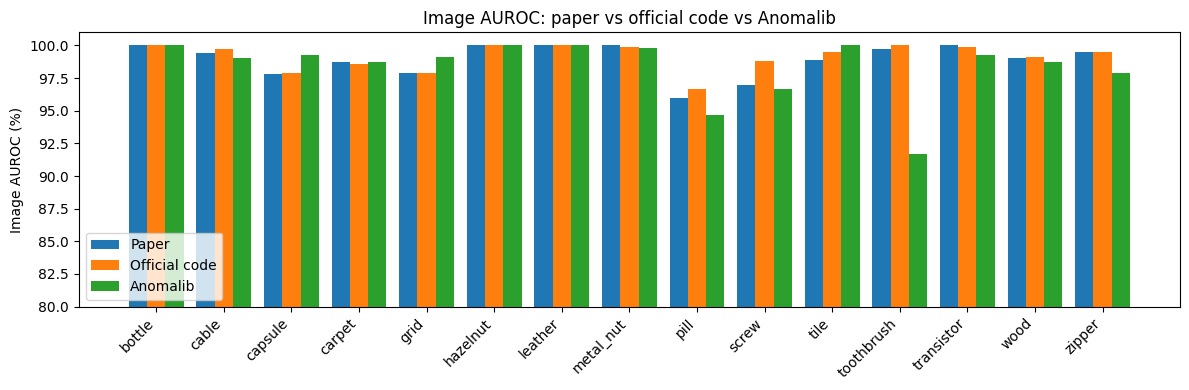

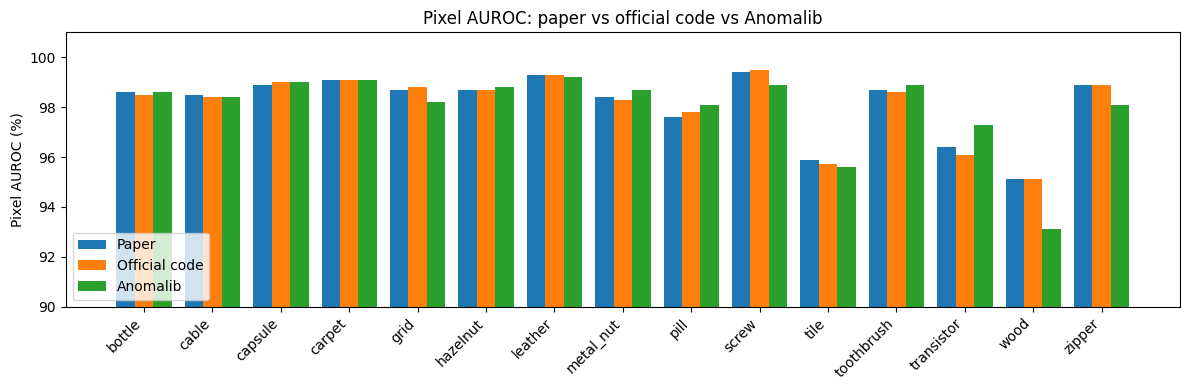

In [8]:
x = np.arange(len(CATEGORIES)); w = 0.27
for metric, label, ymin in [("img", "Image AUROC (%)", 80), ("pix", "Pixel AUROC (%)", 90)]:
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.bar(x - w, comp.loc[CATEGORIES, f"paper_{metric}"], w, label="Paper")
    ax.bar(x, comp.loc[CATEGORIES, f"official_{metric}"], w, label="Official code")
    ax.bar(x + w, comp.loc[CATEGORIES, f"anomalib_{metric}"], w, label="Anomalib")
    ax.set_xticks(x); ax.set_xticklabels(CATEGORIES, rotation=45, ha="right")
    # y axis doesn't start at 0, so small gaps are visible
    ax.set_ylim(ymin, 101); ax.set_ylabel(label); ax.legend(loc="lower left")
    ax.set_title(f"{label.split(' (')[0]}: paper vs official code vs Anomalib")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/bars_{metric}.png", dpi=200); plt.show()

Cell 9: difference from the paper for each implementation

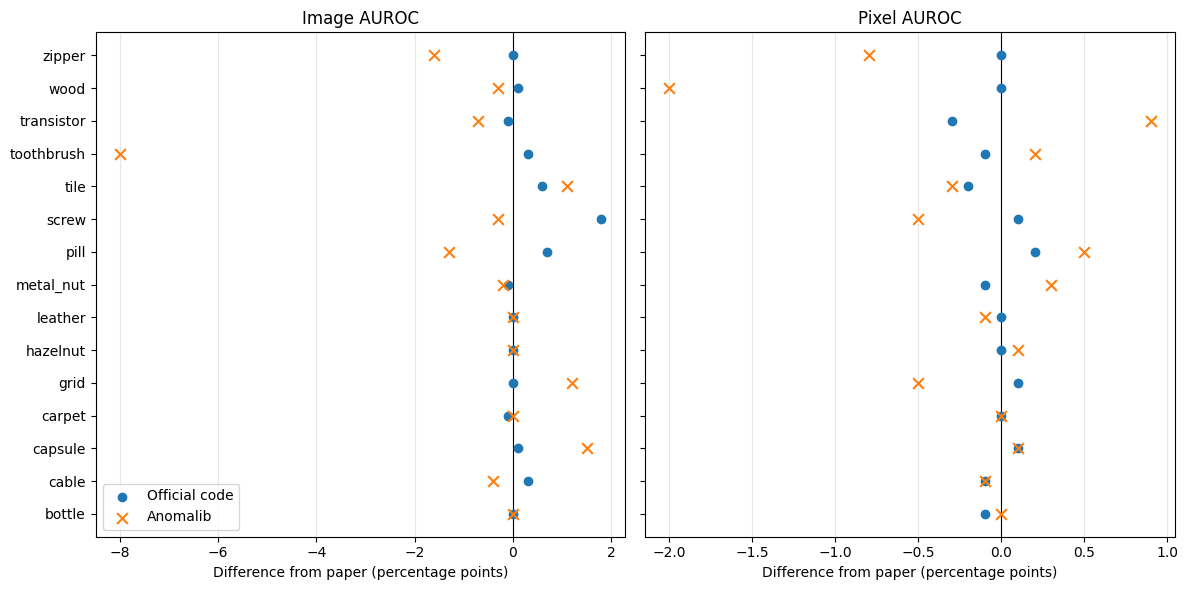

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
y = np.arange(len(CATEGORIES))
for ax, metric, title in [(axes[0], "img", "Image AUROC"), (axes[1], "pix", "Pixel AUROC")]:
    paper = comp.loc[CATEGORIES, f"paper_{metric}"]
    ax.scatter(comp.loc[CATEGORIES, f"official_{metric}"] - paper, y, label="Official code", zorder=3)
    ax.scatter(comp.loc[CATEGORIES, f"anomalib_{metric}"] - paper, y, marker="x", s=60, label="Anomalib", zorder=3)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_yticks(y); ax.set_yticklabels(CATEGORIES); ax.invert_yaxis()
    ax.set_xlabel("Difference from paper (percentage points)"); ax.set_title(title)
    ax.grid(axis="x", alpha=0.3)
axes[0].legend(loc="lower left")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/diff_official_vs_anomalib.png", dpi=200); plt.show()

Cell 10: heatmaps from the official code (re-runs 3 categories with image saving on)

In [13]:
%cd /content/patchcore-inspection
# their MVTecDataset has no transform_std / transform_mean, so use the same
# ImageNet values that mvtec.py itself normalises with (lines 26-27)
p = "bin/run_patchcore.py"
s = open(p).read()
s = s.replace('dataloaders["testing"].dataset.transform_std', '[0.229, 0.224, 0.225]')
s = s.replace('dataloaders["testing"].dataset.transform_mean', '[0.485, 0.456, 0.406]')
open(p, "w").write(s)
!git diff

/content/patchcore-inspection
diff --git a/bin/run_patchcore.py b/bin/run_patchcore.py
index 8666b2b..de56307 100644
--- a/bin/run_patchcore.py
+++ b/bin/run_patchcore.py
@@ -146,10 +146,10 @@ def run(
 
                 def image_transform(image):
                     in_std = np.array(
-                        dataloaders["testing"].dataset.transform_std
+                        [0.229, 0.224, 0.225]
                     ).reshape(-1, 1, 1)
                     in_mean = np.array(
-                        dataloaders["testing"].dataset.transform_mean
+                        [0.485, 0.456, 0.406]
                     ).reshape(-1, 1, 1)
                     image = dataloaders["testing"].dataset.transform_img(image)
                     return np.clip(


In [14]:
%%bash
cd /content/patchcore-inspection
datapath=/content/datasets/MVTecAD
PYTHONPATH=src python bin/run_patchcore.py --gpu 0 --seed 0 --save_segmentation_images \
  --log_group WR50_seg_examples --log_project official results \
  patch_core -b wideresnet50 -le layer2 -le layer3 \
  --pretrain_embed_dimension 1024 --target_embed_dimension 1024 \
  --anomaly_scorer_num_nn 1 --patchsize 3 \
  sampler -p 0.1 approx_greedy_coreset \
  dataset --resize 256 --imagesize 224 -d bottle -d screw -d toothbrush mvtec $datapath

INFO:__main__:Command line arguments: bin/run_patchcore.py --gpu 0 --seed 0 --save_segmentation_images --log_group WR50_seg_examples --log_project official results patch_core -b wideresnet50 -le layer2 -le layer3 --pretrain_embed_dimension 1024 --target_embed_dimension 1024 --anomaly_scorer_num_nn 1 --patchsize 3 sampler -p 0.1 approx_greedy_coreset dataset --resize 256 --imagesize 224 -d bottle -d screw -d toothbrush mvtec /content/datasets/MVTecAD
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
INFO:__main__:Evaluating dataset [mvtec_bottle] (1/3)...
/usr/local

212 segmentation images found


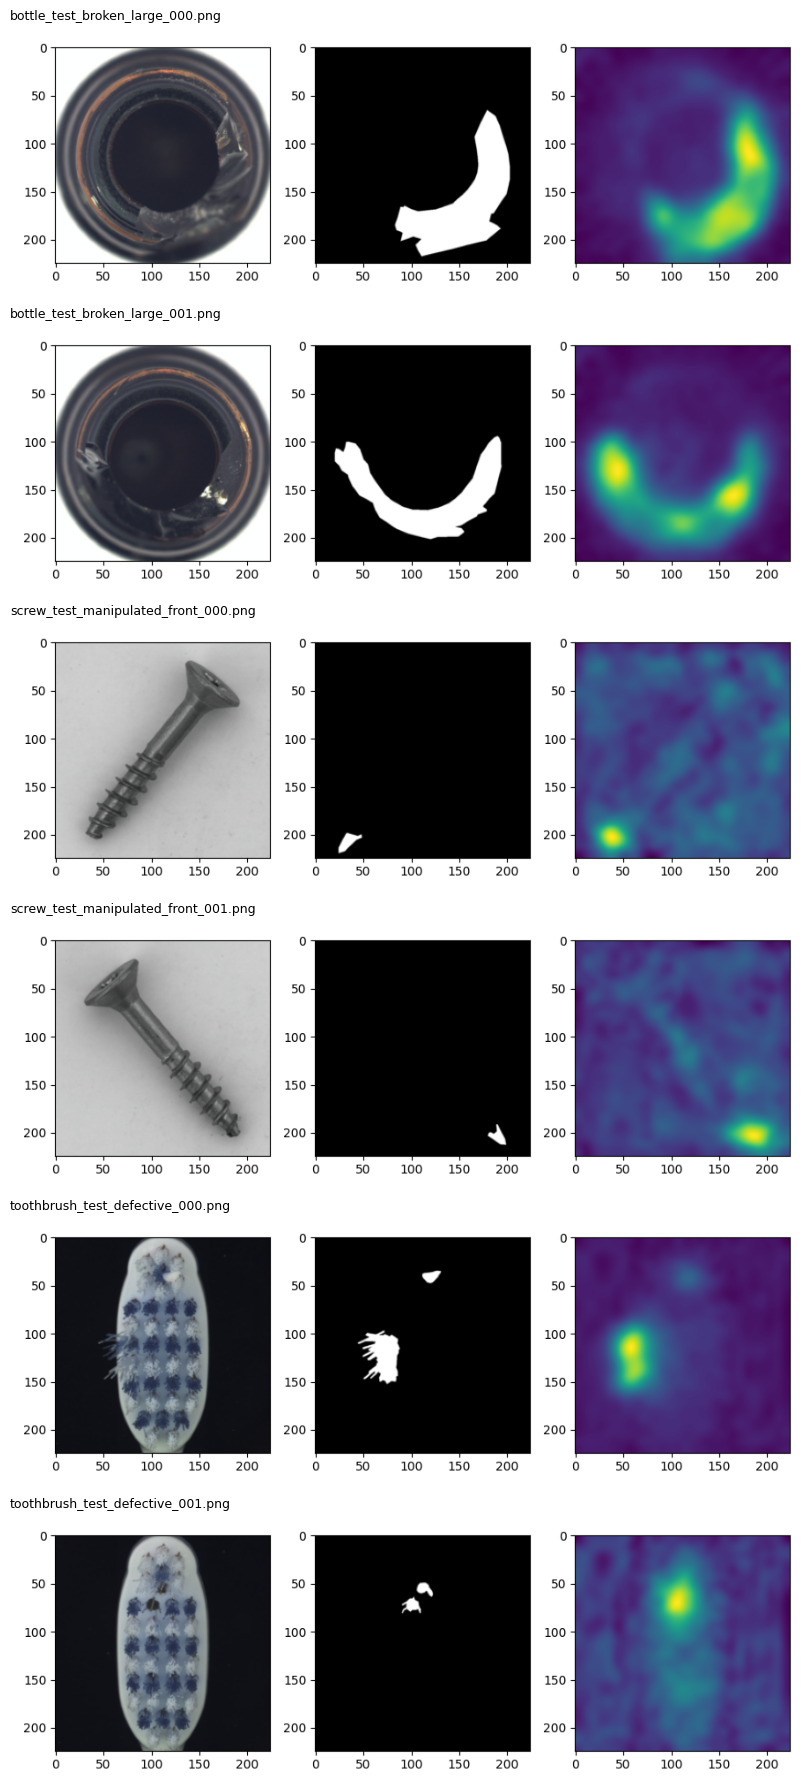

In [15]:
import os, shutil
from PIL import Image as PILImage

seg = [p for p in glob.glob("/content/patchcore-inspection/results/official/WR50_seg_examples*/**/*.*", recursive=True)
       if p.lower().endswith((".png", ".jpg")) and "good" not in p]
print(len(seg), "segmentation images found")

SEG_DIR = f"{OUT_DIR}/heatmaps"; os.makedirs(SEG_DIR, exist_ok=True)
picked = []
for c in ["bottle", "screw", "toothbrush"]:
    picked += [p for p in sorted(seg) if c in p][:2]
for p in picked:
    shutil.copy(p, SEG_DIR)

fig, axes = plt.subplots(len(picked), 1, figsize=(10, 3 * len(picked)))
for ax, p in zip(np.atleast_1d(axes), picked):
    ax.imshow(PILImage.open(p)); ax.set_title(os.path.basename(p), loc="left", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/official_heatmaps.png", dpi=150); plt.show()

Cell 11: key numbers comparing the two implementations

In [16]:
OFFICIAL_TOTAL_S = 1802   # 30m2s from Cell 5

def stats(img, pix):
    d_img = img - comp.loc[CATEGORIES, "paper_img"]
    d_pix = pix - comp.loc[CATEGORIES, "paper_pix"]
    worst = d_img.abs().idxmax()
    return {
        "Mean image AUROC": round(img.mean(), 1),
        "Mean pixel AUROC": round(pix.mean(), 1),
        "Mean abs. gap to paper, image (pts)": round(d_img.abs().mean(), 2),
        "Mean abs. gap to paper, pixel (pts)": round(d_pix.abs().mean(), 2),
        "Categories within 1 pt of paper (image)": int((d_img.abs() <= 1).sum()),
        "Largest image gap": f"{worst} ({d_img[worst]:+.1f})",
        "Toothbrush image AUROC": round(img["toothbrush"], 1),
        # do both find the same categories hard? 1 = same ranking as the paper
        "Rank agreement with paper (Spearman)": round(img.corr(comp.loc[CATEGORIES, "paper_img"], method="spearman"), 2),
    }

key = pd.DataFrame({
    "Official code": stats(comp.loc[CATEGORIES, "official_img"], comp.loc[CATEGORIES, "official_pix"]),
    "Anomalib": stats(comp.loc[CATEGORIES, "anomalib_img"], comp.loc[CATEGORIES, "anomalib_pix"]),
})
key.loc["Total runtime, 15 categories (s)"] = [OFFICIAL_TOTAL_S, round(anom["fit_s"].sum() + anom["test_s"].sum())]
display(key)

gap = (comp.loc[CATEGORIES, "official_img"] - comp.loc[CATEGORIES, "anomalib_img"]).abs()
print(f"Official vs Anomalib, mean abs. image AUROC gap: {gap.mean():.2f} pts (largest: {gap.idxmax()}, {gap.max():.1f})")

key.to_csv(f"{OUT_DIR}/key_comparison.csv")
key.to_latex(f"{OUT_DIR}/key_comparison.tex")

,Official code,Anomalib
Mean image AUROC,99.2,98.3
Mean pixel AUROC,98.1,98.0
"Mean abs. gap to paper, image (pts)",0.28,1.11
"Mean abs. gap to paper, pixel (pts)",0.09,0.43
Categories within 1 pt of paper (image),14,9
Largest image gap,screw (+1.8),toothbrush (-8.0)
Toothbrush image AUROC,100.0,91.7
Rank agreement with paper (Spearman),0.92,0.55
"Total runtime, 15 categories (s)",1802,2692


Official vs Anomalib, mean abs. image AUROC gap: 1.27 pts (largest: toothbrush, 8.3)


Cell 12: setup differences

In [17]:
setup = pd.DataFrame({
    "Paper": ["256, centre crop 224", "784 (28×28)", "not reported", "not reported", "torchvision ImageNet",
              "greedy coreset + random projection", "faiss", "AUROC, pixel AUROC, PRO",
              "Python 3.7 (paper) / 3.8 (README)", "Tesla V4 (as stated)", "-", "not reported"],
    "Official code (my run)": ["256, centre crop 224", "784 (28×28)", "16,385", "4,704", "torchvision IMAGENET1K_V1",
                               "approx. greedy coreset", "faiss (CPU)", "AUROC, pixel AUROC (no PRO)",
                               "Python 3.13", "Tesla T4", "none, 3 flags dropped", "30 min (CPU search)"],
    "Anomalib 2.6.2 (my run)": ["256, no crop", "1,024 (32×32)", "21,401", "6,144", "timm (Hugging Face Hub)",
                                "k-center greedy", "PyTorch", "AUROC, F1, pixel AUROC, PRO",
                                "Python 3.13", "Tesla T4", "none, library defaults", "incl. dataset download"],
}, index=["Input size", "Patches per image", "Memory bank, bottle (10%)", "Memory bank, toothbrush (10%)",
          "Backbone weights", "Coreset method", "Nearest-neighbour search", "Metrics", "Python", "GPU",
          "Changes needed", "Runtime, 15 categories"])
display(setup)
setup.to_csv(f"{OUT_DIR}/setup_differences.csv")
setup.to_latex(f"{OUT_DIR}/setup_differences.tex")

,Paper,Official code (my run),Anomalib 2.6.2 (my run)
Input size,"256, centre crop 224","256, centre crop 224","256, no crop"
Patches per image,784 (28×28),784 (28×28),"1,024 (32×32)"
"Memory bank, bottle (10%)",not reported,"16,385","21,401"
"Memory bank, toothbrush (10%)",not reported,"4,704","6,144"
Backbone weights,torchvision ImageNet,torchvision IMAGENET1K_V1,timm (Hugging Face Hub)
Coreset method,greedy coreset + random projection,approx. greedy coreset,k-center greedy
Nearest-neighbour search,faiss,faiss (CPU),PyTorch
Metrics,"AUROC, pixel AUROC, PRO","AUROC, pixel AUROC (no PRO)","AUROC, F1, pixel AUROC, PRO"
Python,Python 3.7 (paper) / 3.8 (README),Python 3.13,Python 3.13
GPU,Tesla V4 (as stated),Tesla T4,Tesla T4
